## Imports


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import pickle
import sys
from pathlib import Path

# Import my custom utils.
import simulation_utils
sys.path.insert(0, "/tscc/nfs/home/kflanagan/projects/plip_plop/matrix_correspondance")
import utils
importlib.reload(utils)

<module 'utils' from '/tscc/nfs/home/kflanagan/projects/plip_plop/matrix_correspondance/utils.py'>

## Signal building blocks


In [2]:
SCENARIOS = ["easy_agreement", "pure_displacement", "width_mismatch",
             "local_agreement_plus_unrelated", "broad_signal_plus_peak",
             "local_anticorrelation", "multiple_correspondences", "tie", "custom"]

SHAPES = ["bell", "broad", "double", "plateau", "blip", "dip", "noise"]

## Parameters


In [3]:
# Which scenarios to generate and how many examples of each.
scenarios = SCENARIOS
n_windows_per_scenario = 2
seed = 4172

# Average signal height and its window-to-window / peak-to-peak variation.
signal_level = 0.75
signal_variation = 0.15

# Point noise plus low-frequency drift. This does not control structural variation.
noise_level = 0.005

# Inclusive bounds for the number of local features in each window.
peak_count_range = (1, 3)
unrelated_peak_count_range = (1, 3)

# Bounds controlling peak location, width, and ordinary displacement.
location_range = (20, 280)
width_range = (6, 24)
displacement_range = (5, 30)

# Distance and strength tolerance between the two tie solutions.
tie_displacement_range = (30, 90)
tie_strength_variation = 0.03

# Used only by the custom scenario.
shape_a = "bell"
shape_b = "bell"

simulation_parameters = dict(
    signal_level=signal_level, signal_variation=signal_variation, noise_level=noise_level,
    peak_count_range=peak_count_range, unrelated_peak_count_range=unrelated_peak_count_range,
    location_range=location_range, width_range=width_range, displacement_range=displacement_range,
    tie_displacement_range=tie_displacement_range,
    tie_strength_variation=tie_strength_variation, shape_a=shape_a, shape_b=shape_b, n=300
)

rng = np.random.default_rng(seed)
windows = {scenario: [simulation_utils.simulate_pair(scenario, rng, **simulation_parameters)
                      for _ in range(n_windows_per_scenario)]
           for scenario in scenarios}


## Plots


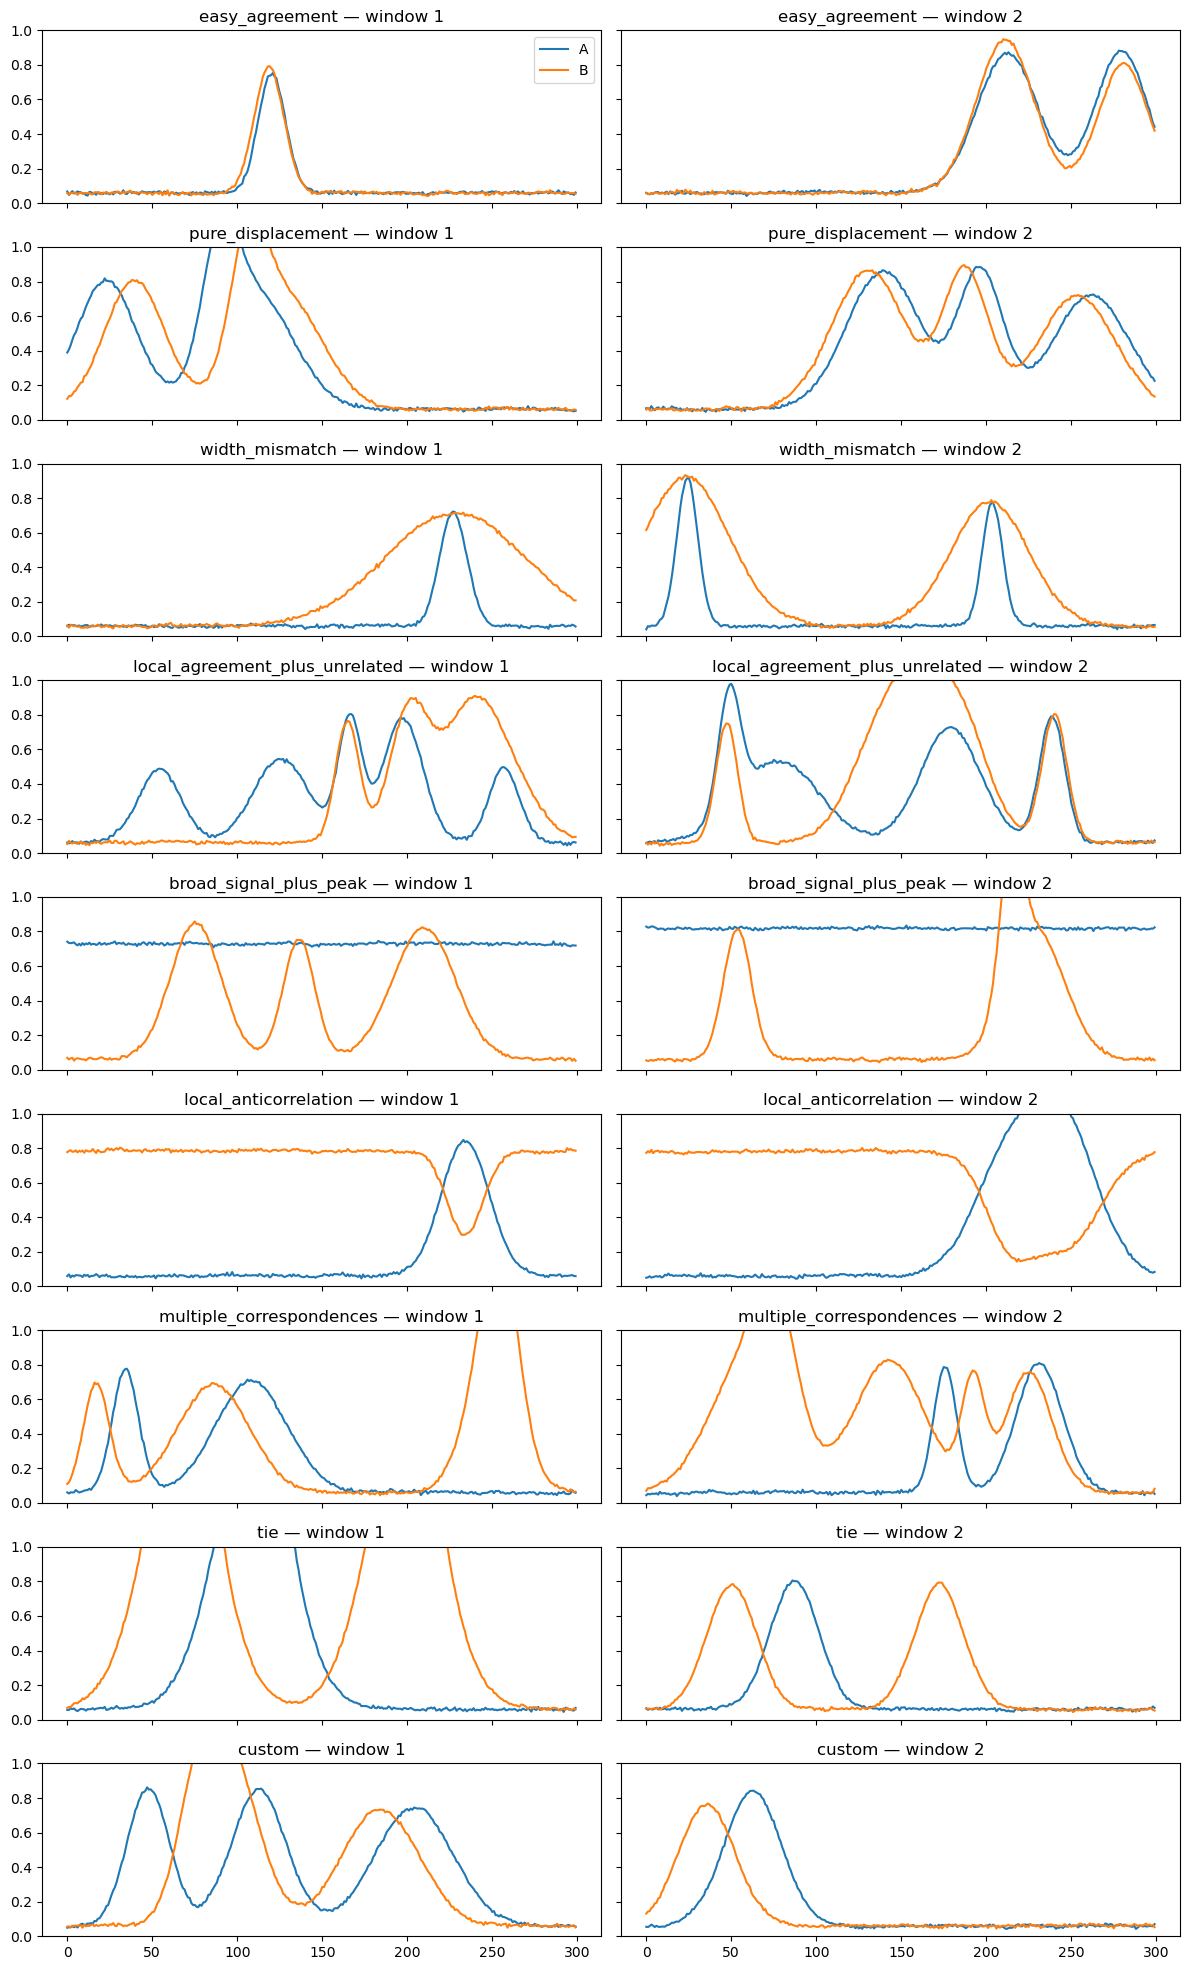

In [4]:
fig, axes = plt.subplots(len(scenarios), n_windows_per_scenario, figsize=(12, 2.2 * len(scenarios)),
                         sharex=True, sharey=True, squeeze=False)

for row, scenario in enumerate(scenarios):
    for col, (a, b) in enumerate(windows[scenario]):
        axes[row, col].plot(a, label="A", lw=1.5)
        axes[row, col].plot(b, label="B", lw=1.5)
        axes[row, col].set_title(f"{scenario} — window {col + 1}")
        axes[row, col].set_ylim(0, 1)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

## Island selection


300
300


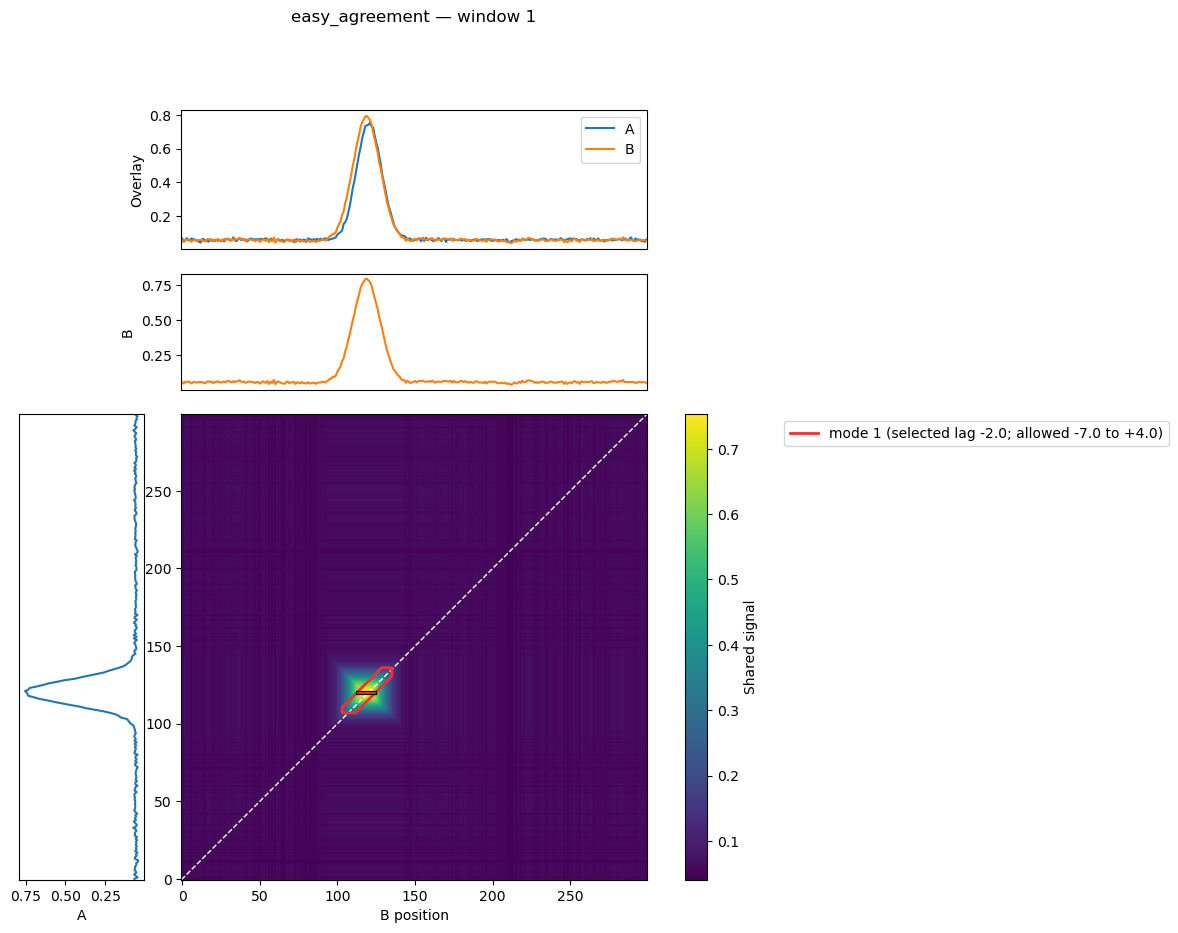

300
300


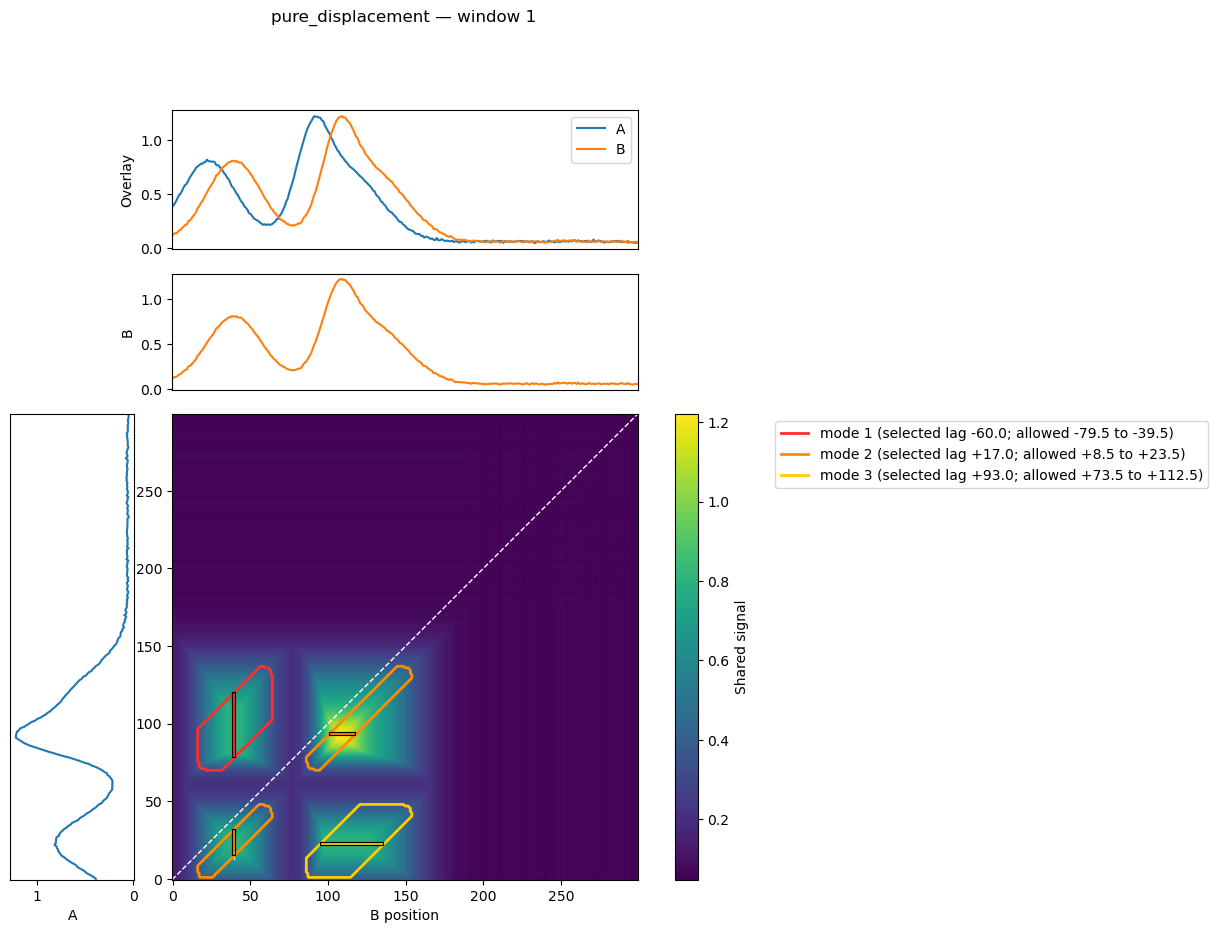

300
300


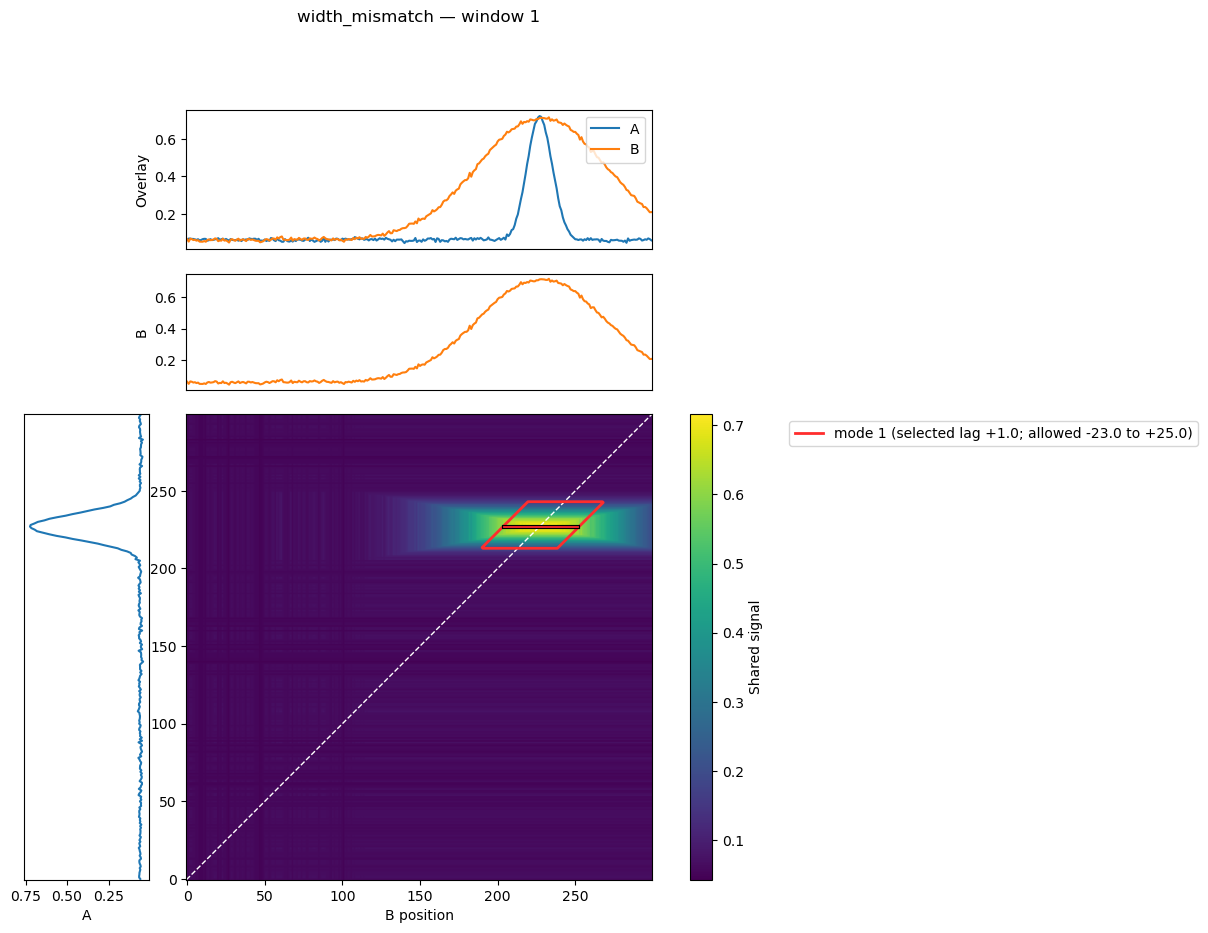

300
300


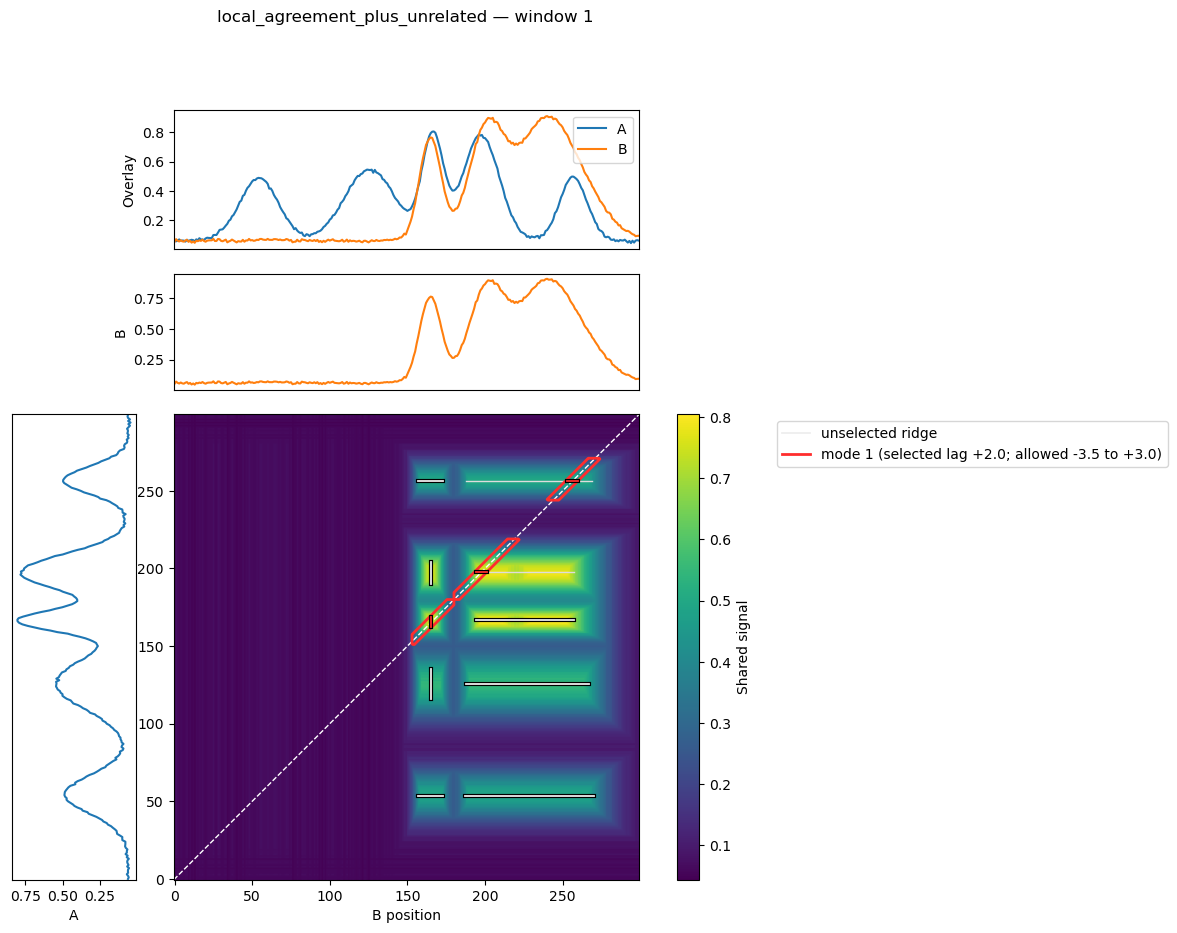

300
300


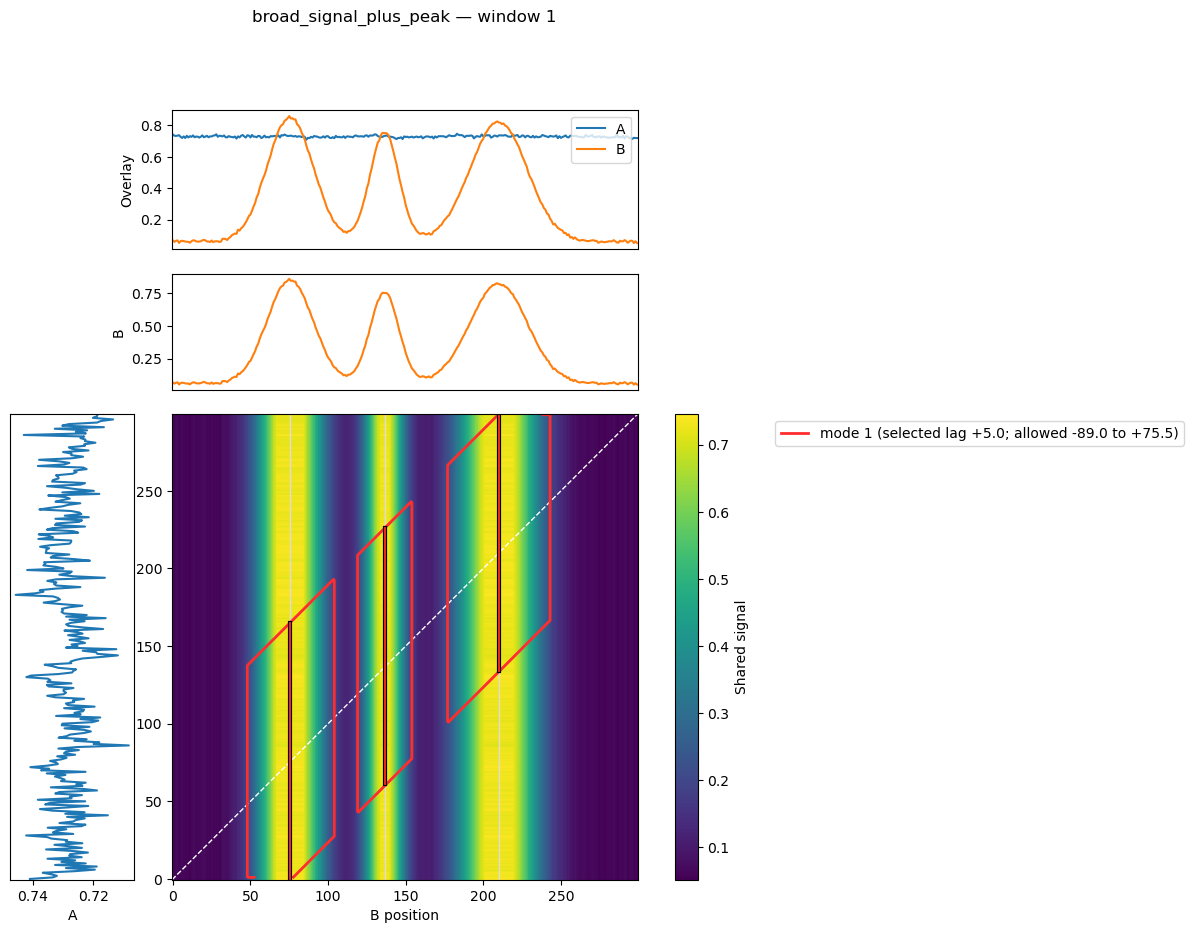

300
300


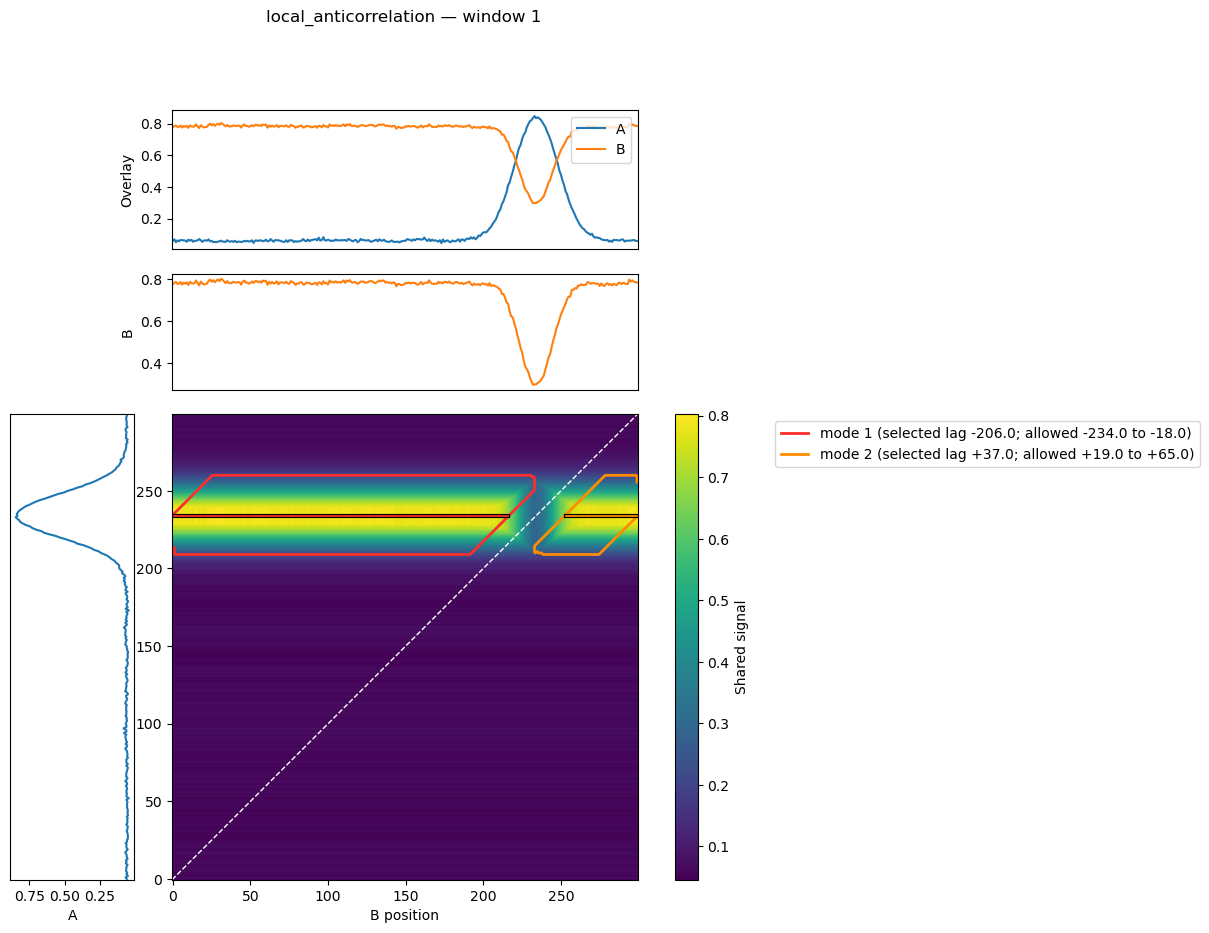

300
300


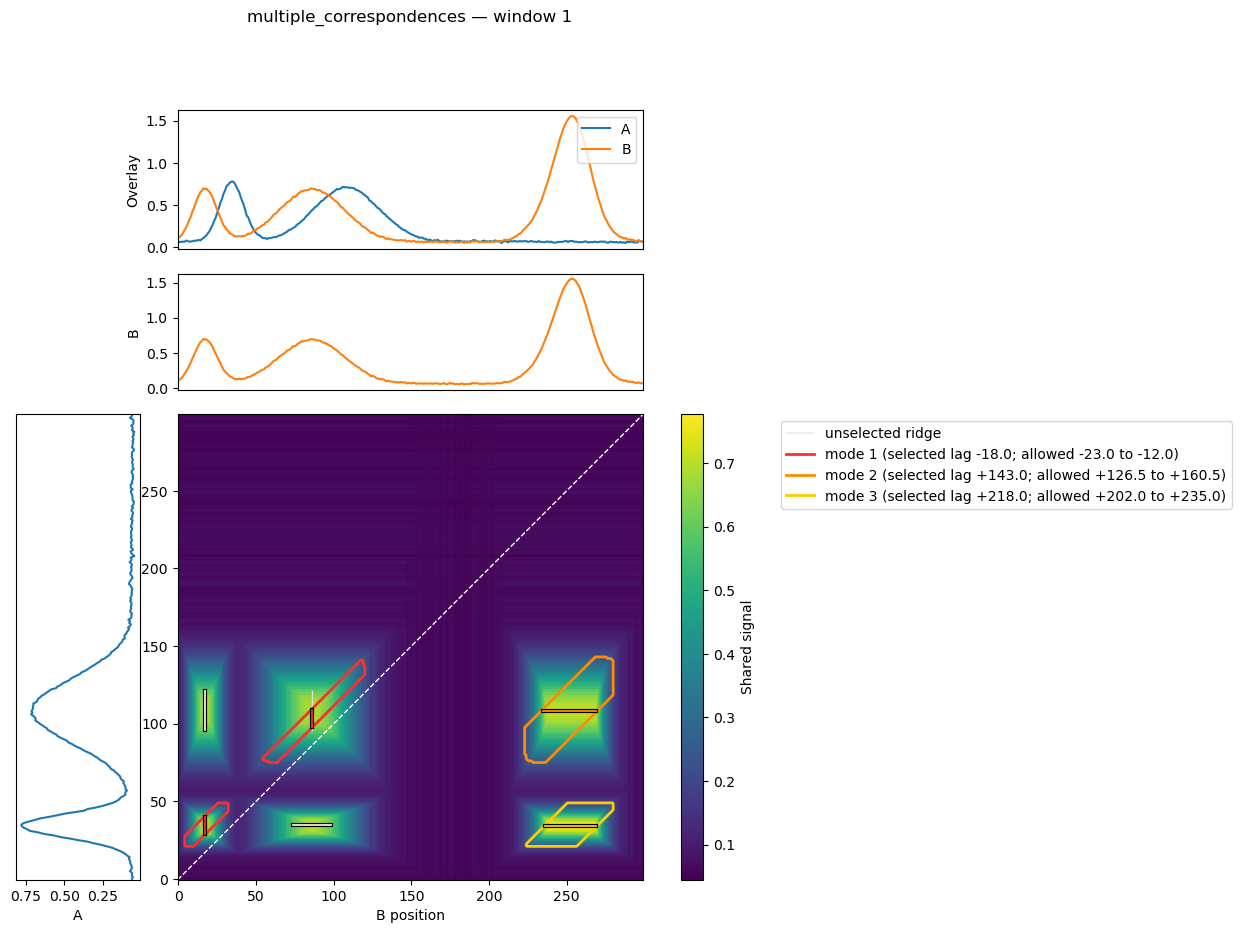

300
300


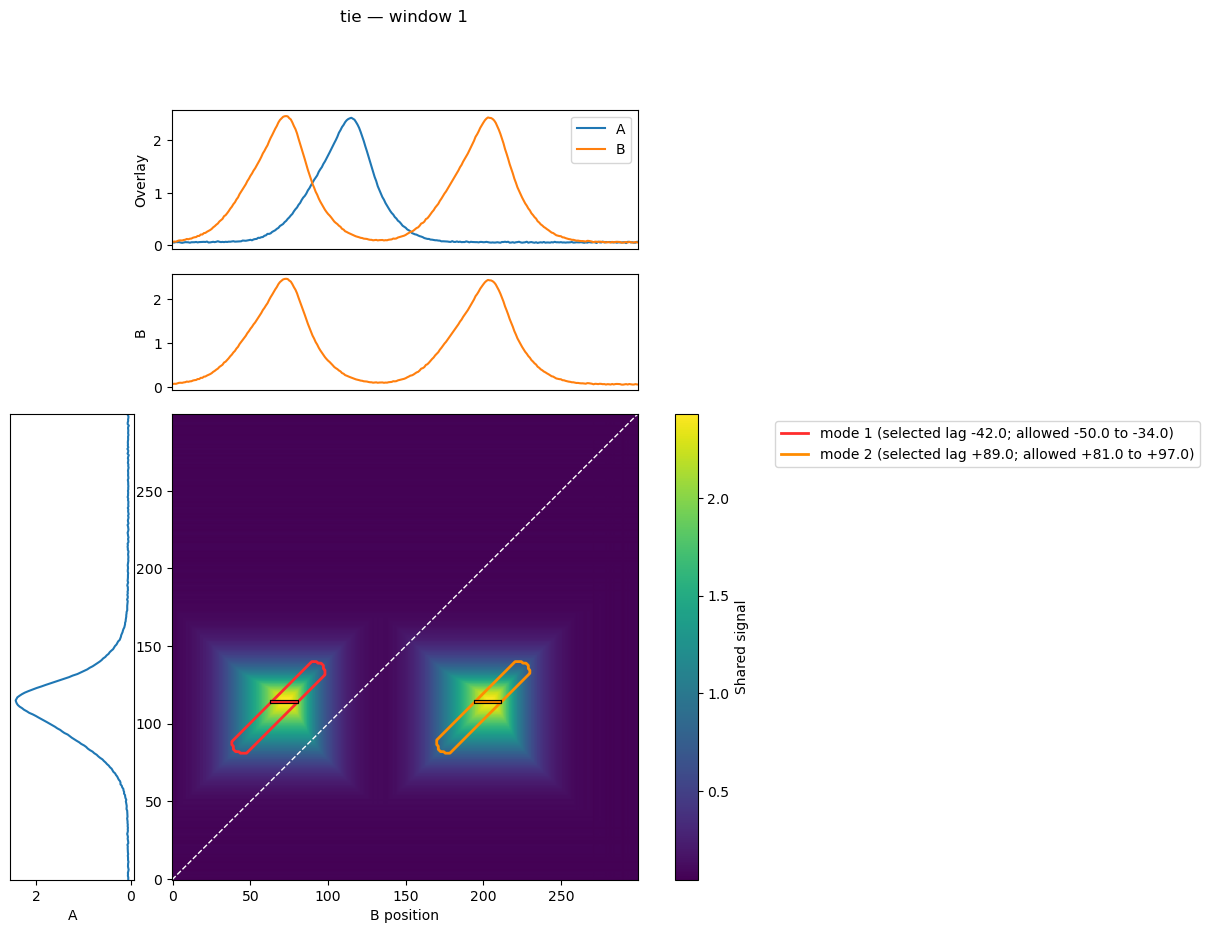

300
300


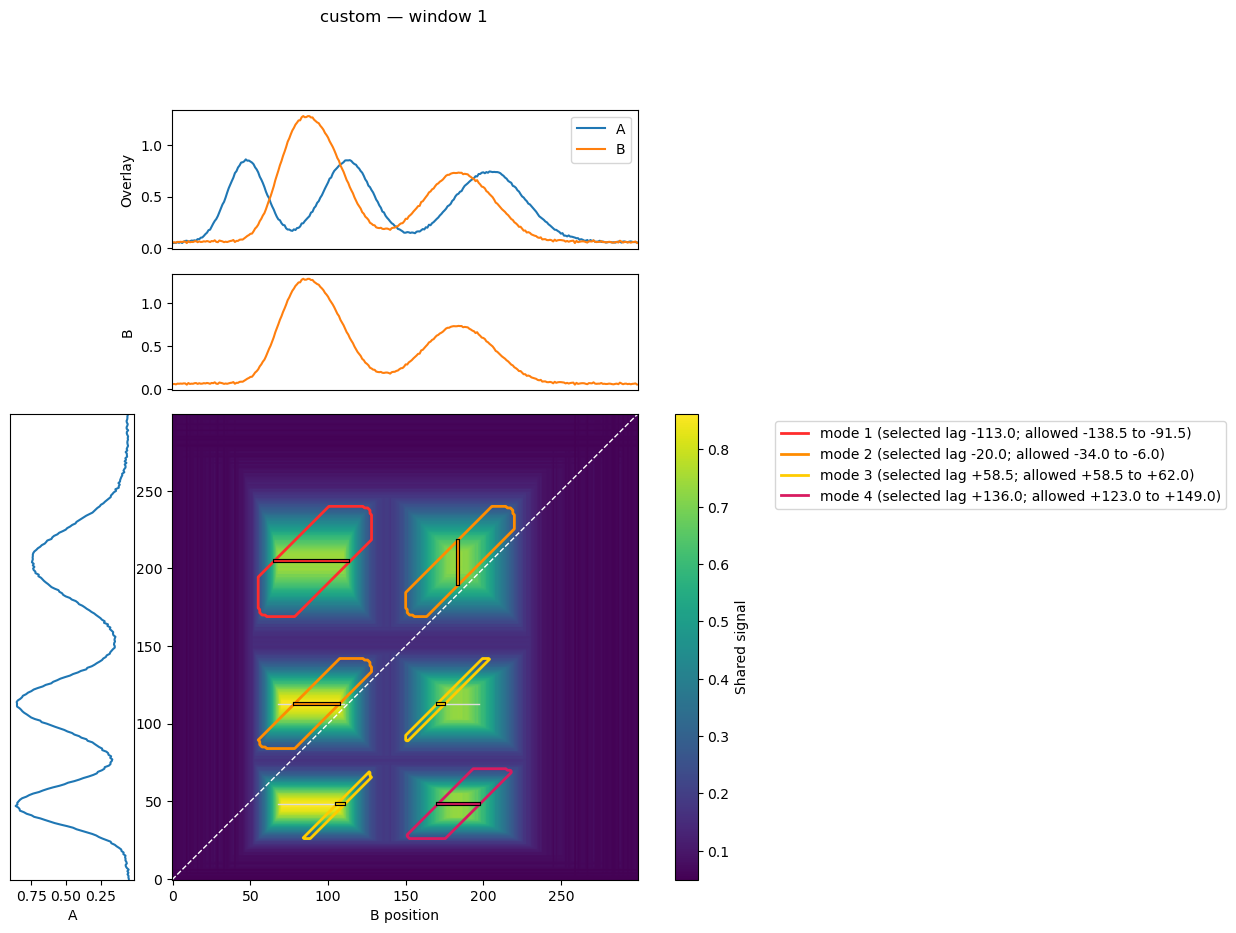

In [5]:
# Run one compact end-to-end island analysis per selected simulated window.
island_scenarios = scenarios
island_windows_per_scenario = 1

island_parameters = dict(
    seed_threshold_fraction=0.4, growth_threshold_fraction=0.25,
    max_weak_distance=5, gap_tolerance=1, shape_balance_power=1.05,
    ridge_fraction=0.85,
    split_prominence_fraction=0.25, split_min_peak_fraction=0.5,
    split_min_peak_distance=8, split_min_seed_area=5,
    displacement_fold_threshold=2.0,
    mode_score_fraction=0.33
)

island_results = {}
for scenario in island_scenarios:
    island_results[scenario] = []
    for i, (a, b) in enumerate(windows[scenario][:island_windows_per_scenario]):
        print(len(a))
        print(len(b))
        result = utils.identify_islands(
            a, b, title=f"{scenario} — window {i + 1}", **island_parameters
        )
        island_results[scenario].append(result)


In [7]:
simulations = ["broad_signal_plus_peak", "local_agreement_plus_unrelated", "multiple_correspondences",
               "width_mismatch", "easy_agreement", "local_anticorrelation", "pure_displacement"]

for name in simulations:
    with open(f"../pickles/sim_{name}.pkl", "wb") as f:
        pickle.dump(island_results[name][0], f, protocol=pickle.HIGHEST_PROTOCOL)

## Explore one scenario


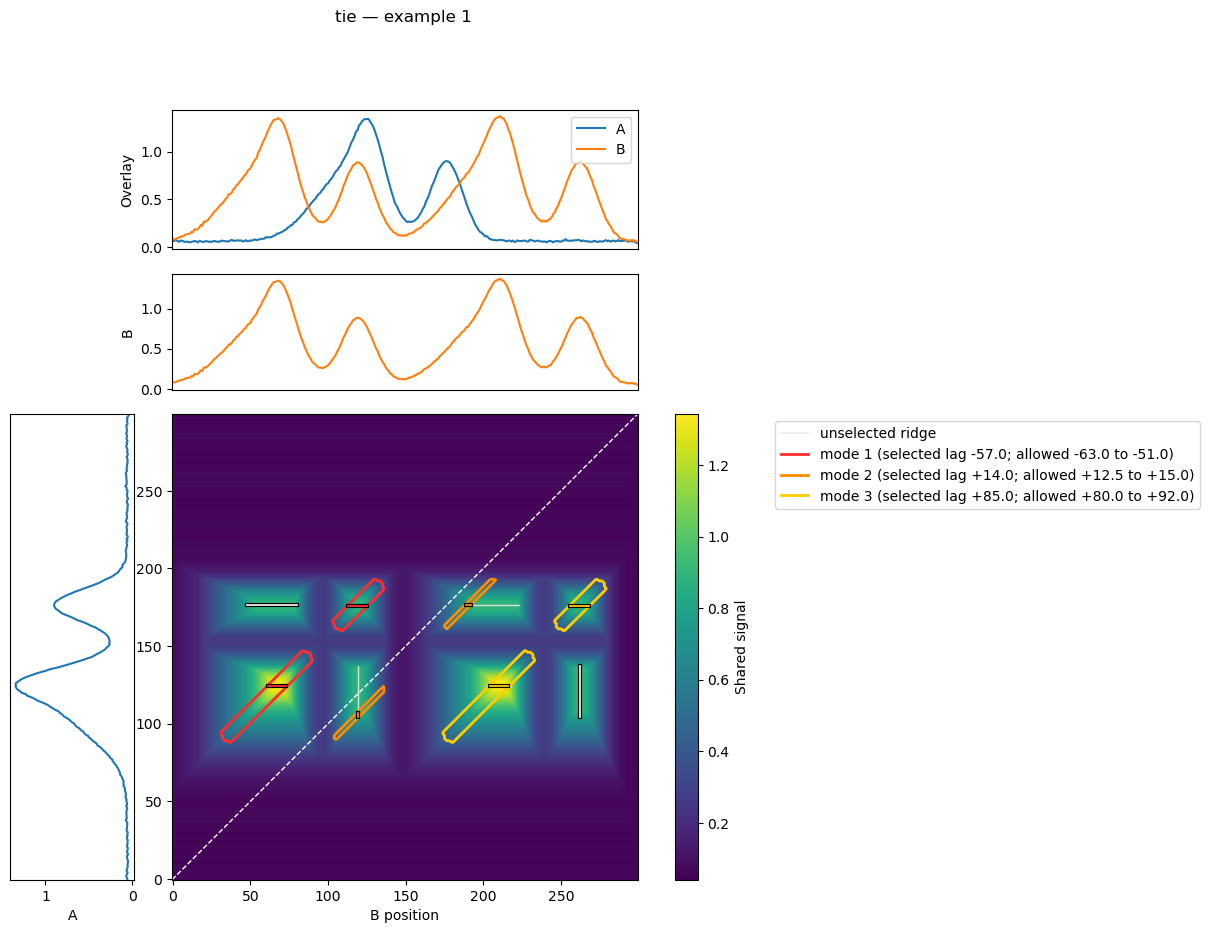

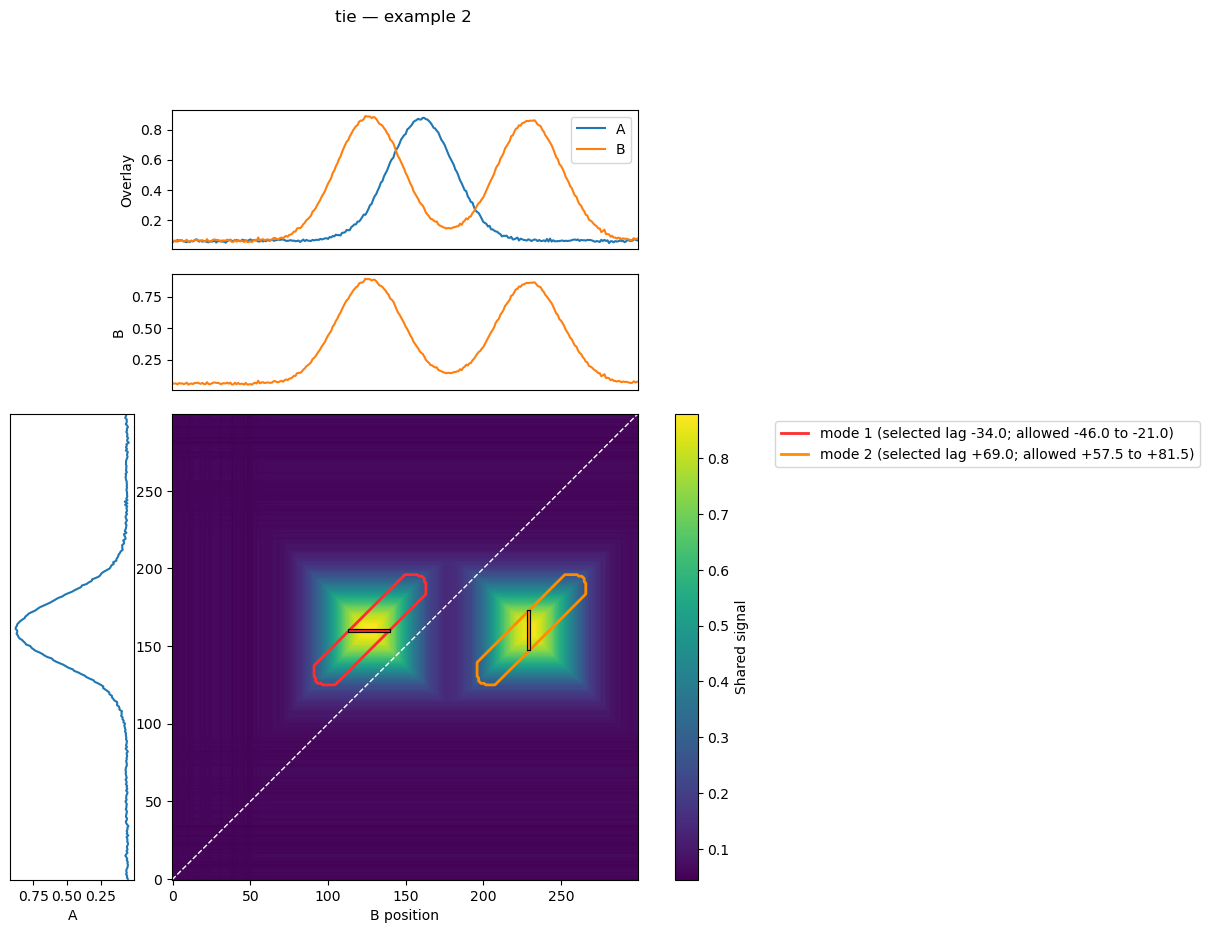

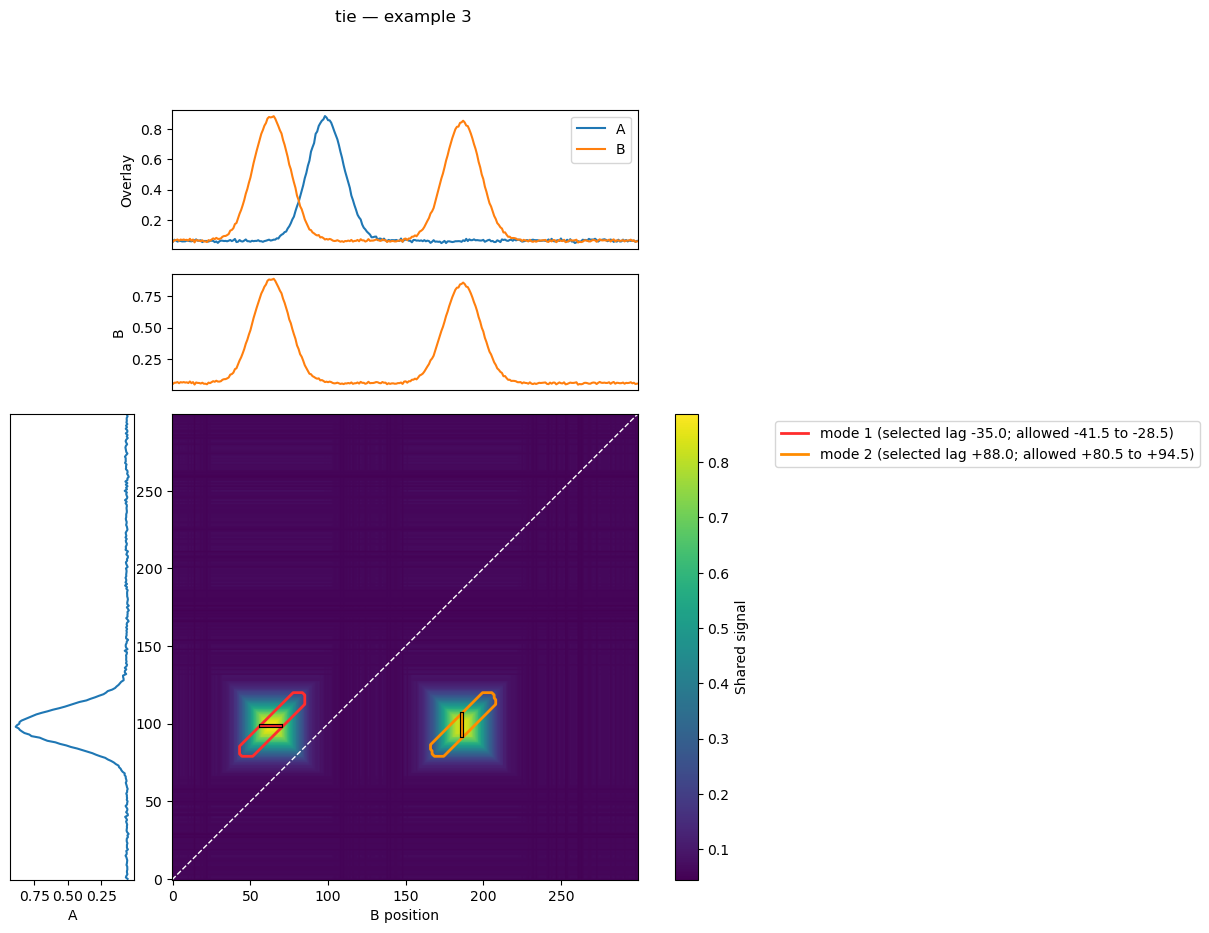

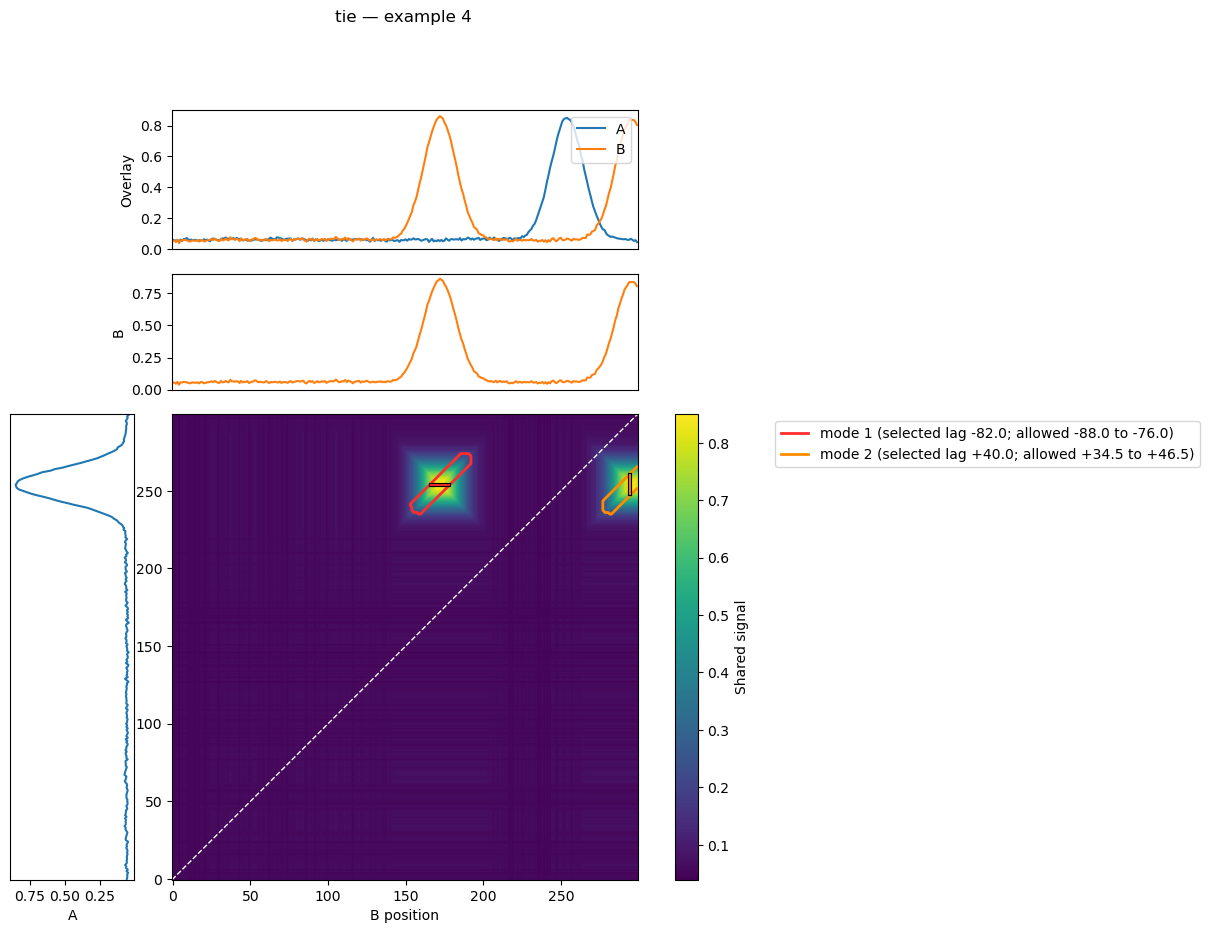

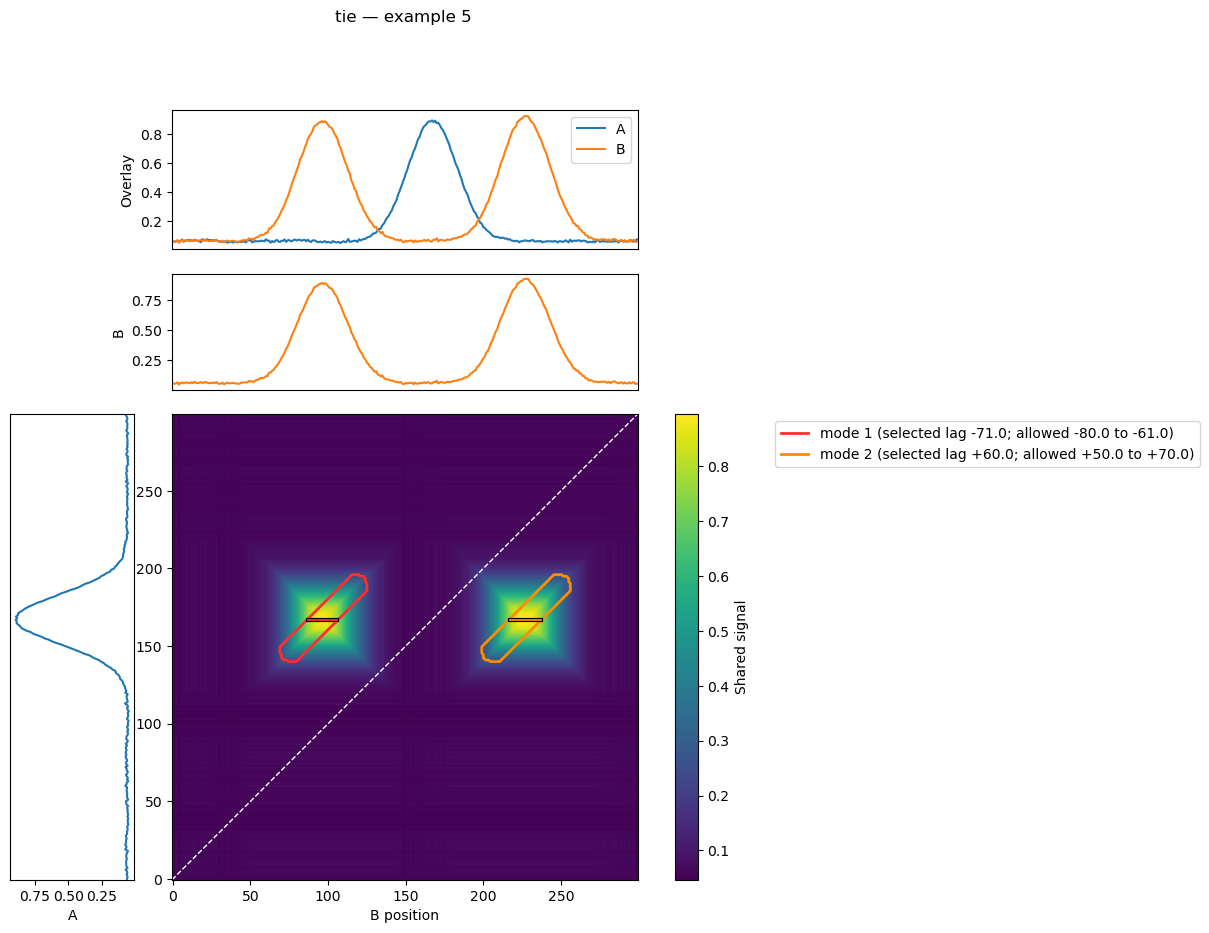

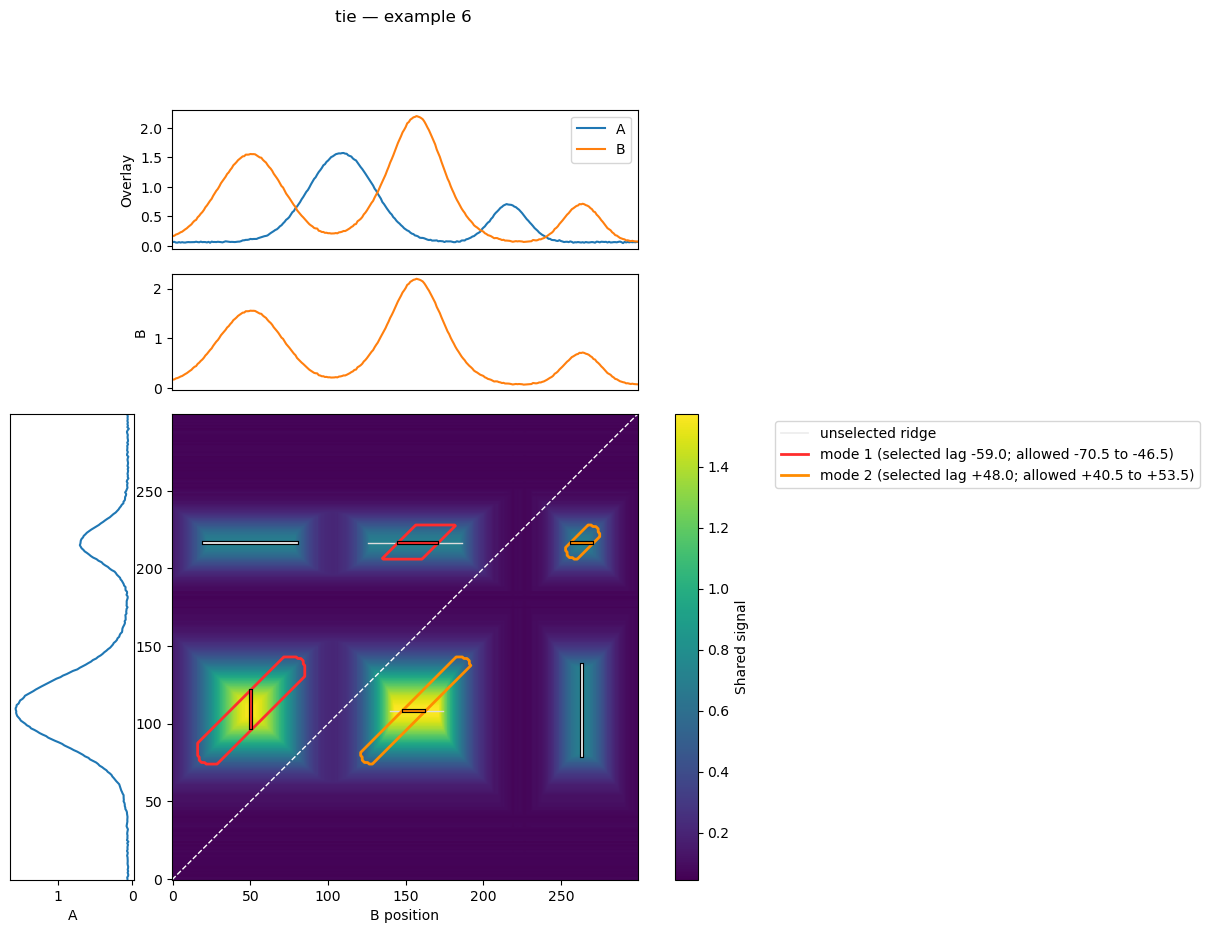

In [9]:
# Generate several new heatmaps for one scenario.
scenario_to_explore = "tie"
n_heatmaps = 6
explore_rng = np.random.default_rng(seed + 1)

explore_results = []
for i in range(n_heatmaps):
    a, b = simulation_utils.simulate_pair(scenario_to_explore, explore_rng, **simulation_parameters)
    result = utils.identify_islands(
        a, b, title=f"{scenario_to_explore} — example {i + 1}", **island_parameters
    )
    explore_results.append(result)
